# Calculate Empirical Semi-Variogram

*Section 3 — Vector data and zonal statistics, notebook 2 of 2.* Previous: `01_zonal_statistics.ipynb`. Next: `04_image_classification` (the first notebook of section 4, rule-based classification).

**You will learn:**
- how to create random sample points within a radius or a bounding box (`rsgispy.vector.create`);
- how to populate the points with values from a DEM (`rsgispy.zonalstats.point`);
- how to split points into sets by direction and add distance/angle attributes (`rsgispy.vector.attrs`, `rsgispy.vector.stats`);
- how to calculate empirical semi-variograms (`rsgispy.vector.stats.calc_empirical_semivariogram`) and plot them (`rsgispy.tools.stats.plot_semivariogram`).

**Before you start:** extracting image values to points from `01_zonal_statistics.ipynb`. The semi-variogram is calculated with [scikit-gstat](https://scikit-gstat.readthedocs.io), which is installed with the rsgispy `stats` extra (`pip install "rsgispy[stats]"`).

**Data:** `../data/dem_10m_osgb.tif` (10 m DEM around Aberystwyth, British National Grid).

**Run time:** less than 1 minute.

## Introduction

The empirical semi-variogram is a visual tool for quantifying spatial covariance.
Semi-variances are binned for distance intervals. The average values for
semi-variance and distance interval can be fit to mathematical models designed
to explain how semivariance changes over distance.

![Explaination of a Semivariogram](figures/semivariogram_explaination.jpg)

For this notebook the following steps will be carried out:

    1. A set of random points within a radius will be generated
    2. The points will be populated with the elevation from a DEM
    3. The points will be split into sets using the angle to allow comparison of the north-south and east-west structures in the DEM
    4. Semi-variograms will be calculated for the whole dataset and the north-south and east-west sets.

All the vector layers created are written as GeoPackage files in the `outputs` directory.

## 1. Import Modules

In [1]:
%matplotlib inline
import os

import geopandas
import matplotlib.pyplot as plt

import rsgispy
import rsgispy.mapping.layout as map_layout
import rsgispy.mapping.raster
import rsgispy.mapping.vector
import rsgispy.vector.attrs
import rsgispy.vector.create
import rsgispy.tools.plotting
import rsgispy.tools.stats
import rsgispy.vector.stats
import rsgispy.zonalstats.point

# All the outputs from this notebook are written to the outputs directory
out_dir = "outputs"
os.makedirs(out_dir, exist_ok=True)

# Output vector files
ran_pts_vec_file = os.path.join(out_dir, "ran_smpl_pts.gpkg")
bbox_pts_vec_file = os.path.join(out_dir, "bbox_ran_pts.gpkg")
bbox_pts_angles_vec_file = os.path.join(out_dir, "bbox_ran_pts_angles.gpkg")
ran_pts_sets_vec_file = os.path.join(out_dir, "ran_smpl_pts_sets.gpkg")

# Some functions will not overwrite an existing output layer, so remove
# the outputs from any previous run of this notebook.
for vec_file in [ran_pts_vec_file, bbox_pts_vec_file, bbox_pts_angles_vec_file, ran_pts_sets_vec_file]:
    if os.path.exists(vec_file):
        os.remove(vec_file)

## 2. Create Random Points

The points are created within a 10 km radius of a centre point. A random seed (`rnd_seed`) is given so that you get the same points each time you run the notebook; set it to `None` to get different points each time.

In [2]:
rsgispy.vector.create.create_random_pts_in_radius(
    centre_x=266500,
    centre_y=278100,
    radius=10000,
    n_pts=5000,
    epsg_code=27700,
    out_vec_file=ran_pts_vec_file,
    out_vec_lyr="ran_smpl_pts",
    out_format="GPKG",
    rnd_seed=42,
    n_pts_multi_bbox=3,
)

### Visualise the Random Points

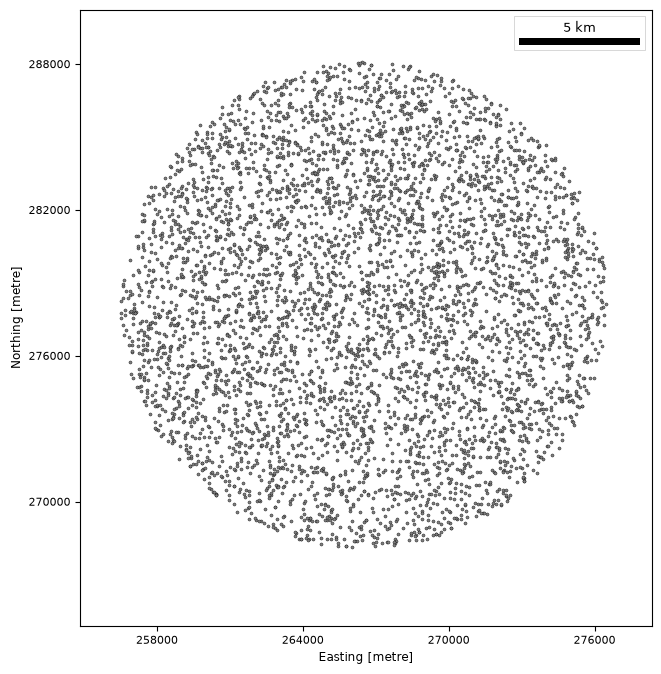

In [3]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(8, 8))
ran_pts_df = geopandas.read_file(ran_pts_vec_file)
bbox = [254845, 278348, 264895, 290234]
_ = rsgispy.mapping.vector.create_vec_lyr_map(ax, ran_pts_df, bbox, vec_markersize=5)

### Random Points in a bounding box

rsgispy also has a function (`rsgispy.vector.create.create_random_pts_in_bbox`) which allows a set of random points to be created within a bounding bbox, this can be run as shown below:

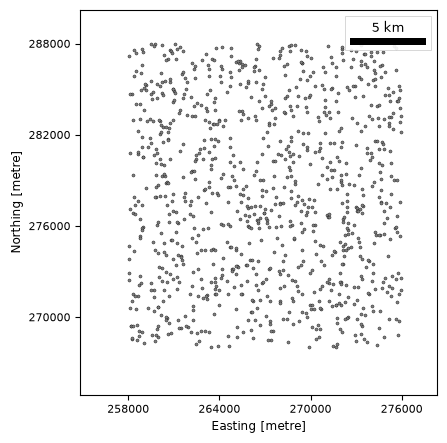

In [4]:
rsgispy.vector.create.create_random_pts_in_bbox(
    bbox=[258000, 276000, 268000, 288000],
    n_pts=1000,
    epsg_code=27700,
    out_vec_file=bbox_pts_vec_file,
    out_vec_lyr="bbox_ran_pts",
    out_format="GPKG",
    rnd_seed=42,
)

# Visualise the result:
fig, ax = plt.subplots(figsize=(5, 5))
ran_pts_df = geopandas.read_file(bbox_pts_vec_file)
bbox = [254845, 278348, 264895, 290234]
_ = rsgispy.mapping.vector.create_vec_lyr_map(ax, ran_pts_df, bbox, vec_markersize=5)

## 3. Zonal Statistics

The next step is to populate the random points with the elevation values from the DEM which will be used to calculate the semi-variogram. As no output file is given, the `elev` column is added to the input file.

In [5]:
rsgispy.zonalstats.point.ext_point_band_values_file(
    vec_file=ran_pts_vec_file,
    vec_lyr="ran_smpl_pts",
    input_img="../data/dem_10m_osgb.tif",
    img_band=1,
    min_thres=0,
    max_thres=2000,
    out_no_data_val=9999,
    out_field="elev",
    reproj_vec=False,
    vec_def_epsg=27700,
)

  0%|          | 0/5000 [00:00<?, ?it/s]

### 3.1 Visual the Points with the Elevation value

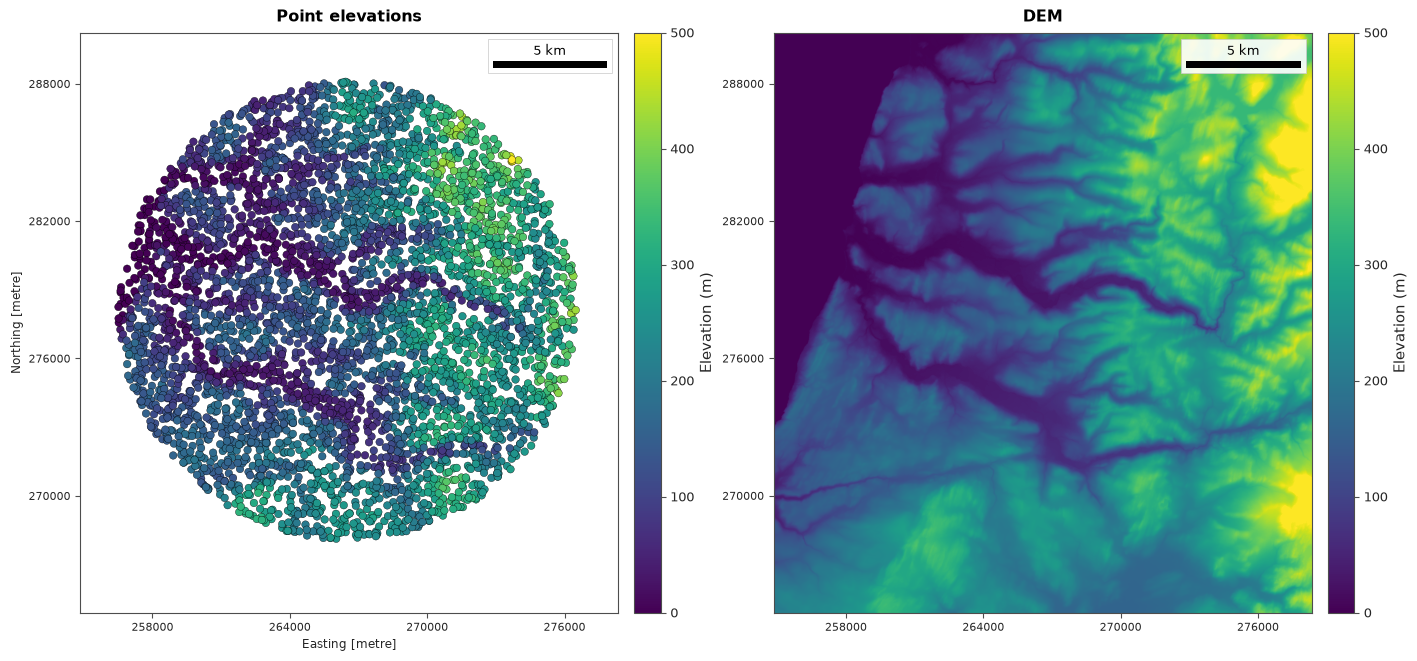

In [6]:
import matplotlib.colors

ran_pts_df = geopandas.read_file(ran_pts_vec_file)
bbox = [254845, 278348, 264895, 290234]

# Colour the points and the DEM with the same colour map and range
# (0 - 500 m), so the point values can be compared with the DEM.
elev_norm = matplotlib.colors.Normalize(vmin=0, vmax=500)

# Create the figure in the rsgispy map style (see
# 02_making_maps/01_intro_matplotlib.ipynb) so the maps and their
# colour bars are laid out neatly.
with rsgispy.tools.plotting.rsgispy_plot_style(plot_type="map"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5))

# show_colour_bar adds a colour bar for the elevation values
_ = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax1,
    ran_pts_df,
    vec_col="elev",
    bbox=bbox,
    vec_fill_cmap="viridis",
    vec_var_norm=elev_norm,
    vec_markersize=30,
    title_str="Point elevations",
    show_colour_bar=True,
    cbar_label="Elevation (m)",
)
_ = rsgispy.mapping.raster.create_raster_cmap_img_map(
    ax2,
    "../data/dem_10m_osgb.tif",
    img_band=1,
    bbox=bbox,
    cmap_name="viridis",
    norm_img_vals=True,
    norm_vmin=0,
    norm_vmax=500,
    title_str="DEM",
    show_colour_bar=True,
    cbar_label="Elevation (m)",
)

## 4. Create Angle Sets

The `create_orthogonal_angle_sets` function uses the angle of each point from the centre (the `angle` column) to put the points into sets: set 1 contains the points within 30 degrees (`angle_half_width`) of north or south (0 and 180 degrees), set 2 the points within 30 degrees of east or west (90 and 270 degrees) and set 0 the rest.

In [7]:
rsgispy.vector.attrs.create_orthogonal_angle_sets(
    vec_file=ran_pts_vec_file,
    vec_lyr="ran_smpl_pts",
    angle_col="angle",
    start_angle=0,
    angle_half_width=30,
    out_vec_file=ran_pts_sets_vec_file,
    out_vec_lyr="ran_smpl_pts_sets",
    out_format="GPKG",
    out_angle_set_col="angle_set",
)

### 4.1 Visualise the Point Sets

Set 1 (north-south) is shown in blue, set 2 (east-west) in red-orange and set 0 (the other points) in grey.

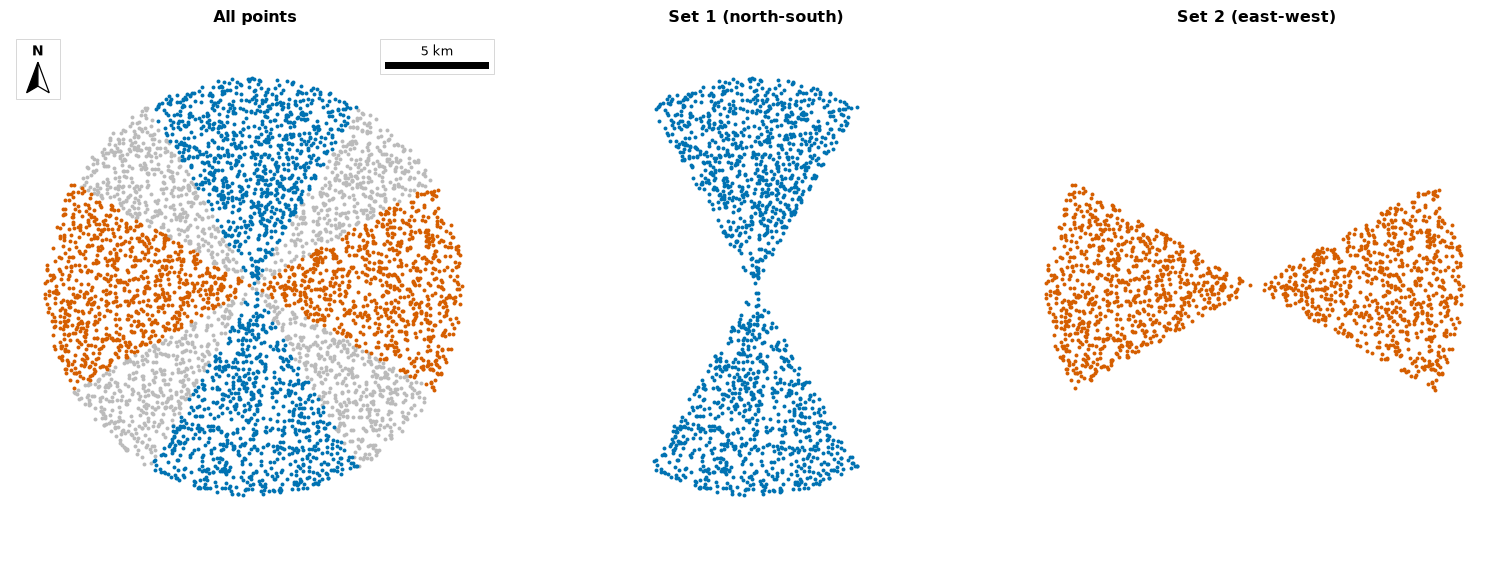

In [8]:
ran_pts_df = geopandas.read_file(ran_pts_sets_vec_file)
bbox = [254845, 278348, 264895, 290234]
ran_pts_set0_df = ran_pts_df[ran_pts_df.angle_set == 0]
ran_pts_set1_df = ran_pts_df[ran_pts_df.angle_set == 1]
ran_pts_set2_df = ran_pts_df[ran_pts_df.angle_set == 2]

# Colours for the sets: grey for set 0 and the first two
# colours of the rsgispy colour cycle for sets 1 and 2.
set_clrs = ["#bbbbbb"] + rsgispy.tools.plotting.CATEGORICAL_COLOURS[:2]

# Draw the three maps side by side with create_map_panels
# (see 02_making_maps/02_maps_from_eo_data.ipynb).
pt_map_kw = {"vec_markersize": 8, "vec_line_widths": 0}
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "vector",
            vec=[ran_pts_set0_df, ran_pts_set1_df, ran_pts_set2_df],
            title="All points",
            map_kw={"vec_fill_clrs": set_clrs, **pt_map_kw},
        ),
        map_layout.MapPanel(
            "vector",
            vec=ran_pts_set1_df,
            title="Set 1 (north-south)",
            map_kw={"vec_fill_clrs": set_clrs[1], **pt_map_kw},
        ),
        map_layout.MapPanel(
            "vector",
            vec=ran_pts_set2_df,
            title="Set 2 (east-west)",
            map_kw={"vec_fill_clrs": set_clrs[2], **pt_map_kw},
        ),
    ],
    bbox=bbox,
)

### 4.2 Populate Angles

The `rsgispy.vector.create.create_random_pts_in_radius` function populates the points
with the distance and angle from the centre point. However, if you are using points from another
source then you can use the `rsgispy.vector.stats.calc_vec_pt_dist_angle` function to populate the angle (and distance). By default the angles are calculated from the centre of the points, but a centre can be given with `x_centre` and `y_centre`.

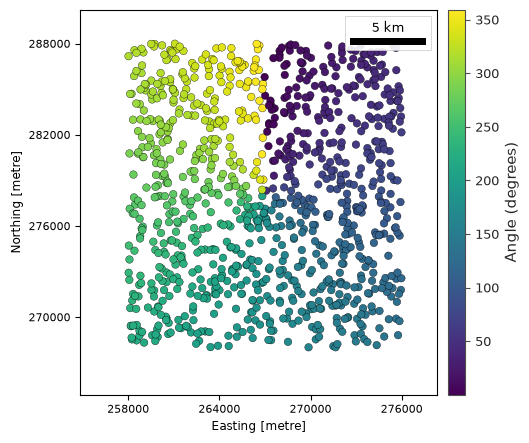

In [9]:
rsgispy.vector.stats.calc_vec_pt_dist_angle(
    vec_file=bbox_pts_vec_file,
    vec_lyr="bbox_ran_pts",
    out_vec_file=bbox_pts_angles_vec_file,
    out_vec_lyr="bbox_ran_pts",
    out_format="GPKG",
    angle_col="angle",
    dist_col="dist",
)

# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(6, 5))
ran_pts_df = geopandas.read_file(bbox_pts_angles_vec_file)
bbox = [254845, 278348, 264895, 290234]
_ = rsgispy.mapping.vector.create_choropleth_vec_lyr_map(
    ax,
    ran_pts_df,
    vec_col="angle",
    bbox=bbox,
    vec_markersize=30,
    show_colour_bar=True,
    cbar_label="Angle (degrees)",
)

## 5. Calculate the Global Semi-Variogram

`calc_empirical_semivariogram` returns a pandas `DataFrame` with the distance, semi-variance and the number of point pairs for each lag; the table is also written to a CSV file (`out_data_file`). It can also save a plot of the semi-variogram (`out_plot_file`), but that figure is closed rather than shown, so to see the plot in the notebook we pass the returned table to `rsgispy.tools.stats.plot_semivariogram`, which also saves the plot when `out_plot_file` is given. The top panel of the plot shows the number of point pairs in each lag.

,distance,semivariance,count
0,352.469620,469.765646,15123
1,704.939241,1371.873146,44776
2,1057.408861,2138.250520,73818
3,1409.878481,2746.838730,100892
4,1762.348102,3200.811624,126911


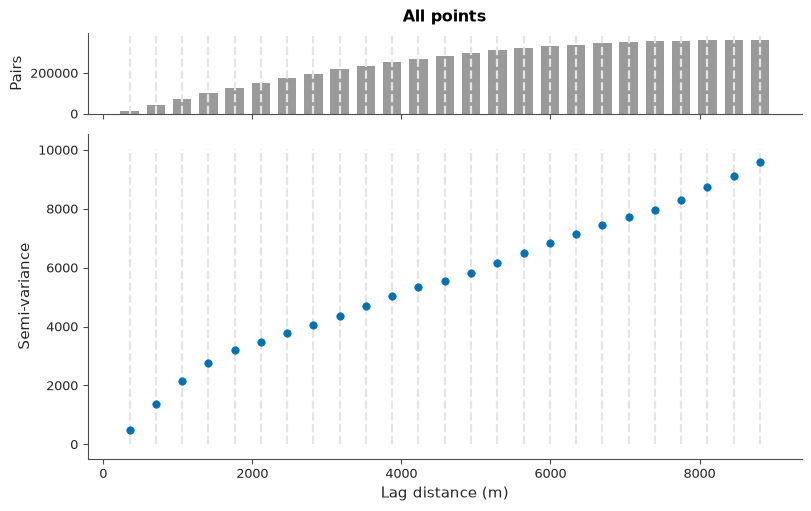

In [10]:
semivario_df = rsgispy.vector.stats.calc_empirical_semivariogram(
    vec_file=ran_pts_sets_vec_file,
    vec_lyr="ran_smpl_pts_sets",
    vals_col="elev",
    pts_sel_col=None,
    pts_sel_val=None,
    out_data_file=os.path.join(out_dir, "semivario_all_pts.csv"),
    max_lag="median",
    n_lags=25,
    normalise_vals=False,
)
fig, axs = rsgispy.tools.stats.plot_semivariogram(
    semivario_df,
    title="All points",
    dist_label="Lag distance (m)",
    out_plot_file=os.path.join(out_dir, "semivario_all_pts_plot.png"),
)
semivario_df.head()

## 6. Calculate the Set-1 (North-South) Semi-Variogram

,distance,semivariance,count
0,288.056247,290.049739,3289
1,576.112495,900.147338,9396
2,864.168742,1553.560184,14807
3,1152.224989,2082.045812,19752
4,1440.281236,2565.060741,23820


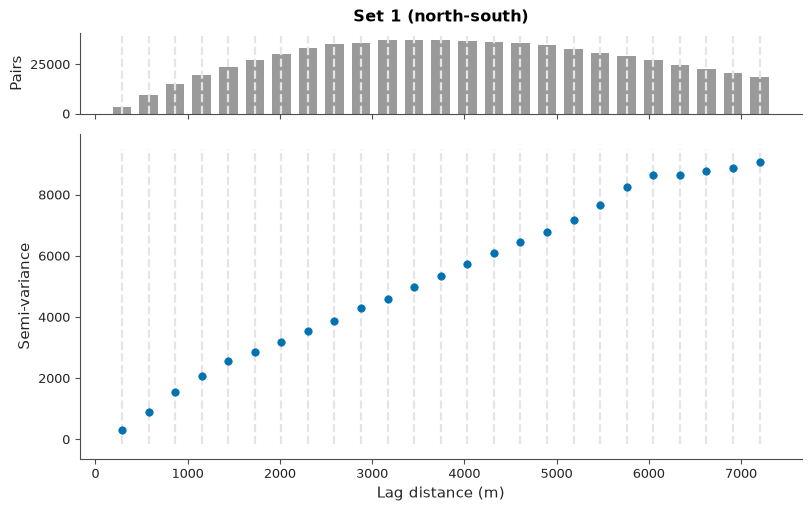

In [11]:
semivario_df = rsgispy.vector.stats.calc_empirical_semivariogram(
    vec_file=ran_pts_sets_vec_file,
    vec_lyr="ran_smpl_pts_sets",
    vals_col="elev",
    pts_sel_col="angle_set",
    pts_sel_val=1,
    out_data_file=os.path.join(out_dir, "semivario_set1_ns.csv"),
    max_lag="median",
    n_lags=25,
    normalise_vals=False,
)
fig, axs = rsgispy.tools.stats.plot_semivariogram(
    semivario_df,
    title="Set 1 (north-south)",
    dist_label="Lag distance (m)",
    out_plot_file=os.path.join(out_dir, "semivario_set1_ns_plot.png"),
)
semivario_df.head()

## 7. Calculate the Set-2 (East-West) Semi-Variogram

,distance,semivariance,count
0,285.930201,363.506250,3410
1,571.860402,1208.585911,9333
2,857.790604,1920.589681,15054
3,1143.720805,2441.248086,19880
4,1429.651006,2920.035987,23887


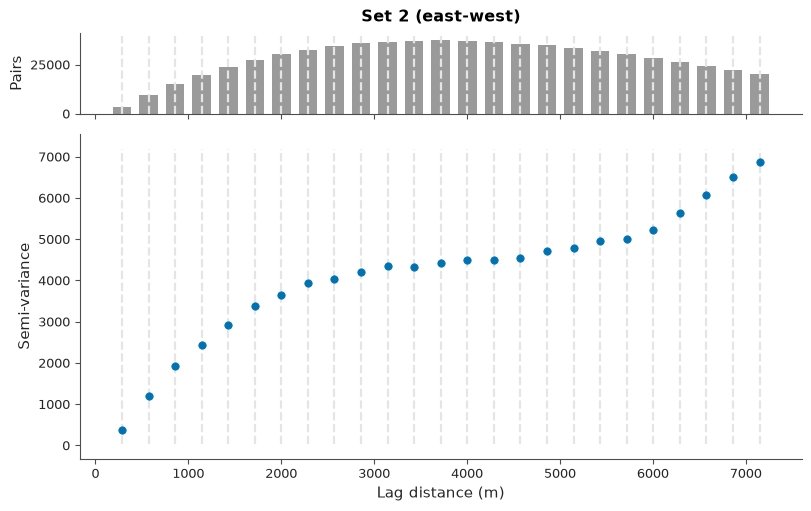

In [12]:
semivario_df = rsgispy.vector.stats.calc_empirical_semivariogram(
    vec_file=ran_pts_sets_vec_file,
    vec_lyr="ran_smpl_pts_sets",
    vals_col="elev",
    pts_sel_col="angle_set",
    pts_sel_val=2,
    out_data_file=os.path.join(out_dir, "semivario_set2_ew.csv"),
    max_lag="median",
    n_lags=25,
    normalise_vals=False,
)
fig, axs = rsgispy.tools.stats.plot_semivariogram(
    semivario_df,
    title="Set 2 (east-west)",
    dist_label="Lag distance (m)",
    out_plot_file=os.path.join(out_dir, "semivario_set2_ew_plot.png"),
)
semivario_df.head()

## 8. Compare the Semi-Variograms

The semi-variograms can also be plotted together from the returned tables, to compare the north-south and east-west structure in the DEM:

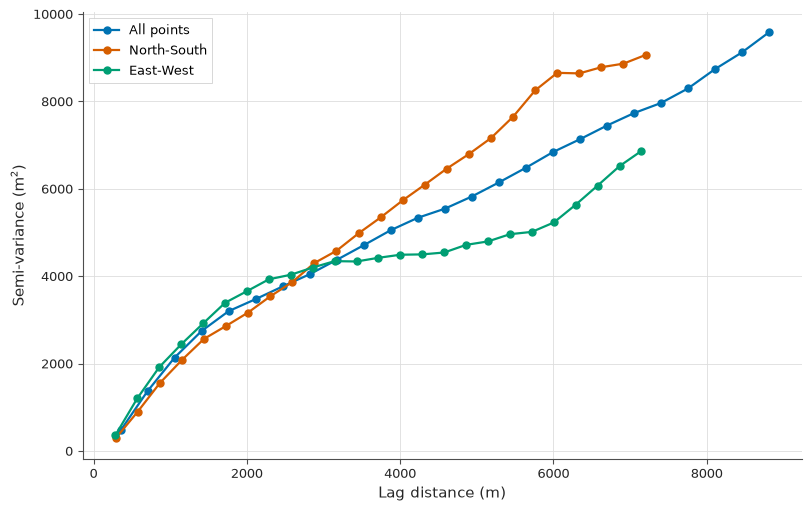

In [13]:
import pandas

# Use the rsgispy plot style (see 02_making_maps/01_intro_matplotlib.ipynb)
# so this plot matches the semi-variogram plots above.
with rsgispy.tools.plotting.rsgispy_plot_style():
    fig, ax = plt.subplots(figsize=(8, 5))
    for name, lbl in [("all_pts", "All points"), ("set1_ns", "North-South"), ("set2_ew", "East-West")]:
        sv_df = pandas.read_csv(os.path.join(out_dir, f"semivario_{name}.csv"))
        ax.plot(sv_df["distance"], sv_df["semivariance"], marker="o", label=lbl)
    ax.set_xlabel("Lag distance (m)")
    ax.set_ylabel("Semi-variance (m$^2$)")
    _ = ax.legend()